In [70]:
import os
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

In [71]:
def read_documents(doc_file):
    docs = []
    labels = []
    with open(doc_file, encoding="utf-8") as f:
        for line in f:
            words = line.strip().split()
            docs.append(words[3:])
            labels.append(words[1])
    return docs, labels


all_docs, all_labels = read_documents(os.path.join("data", "all_sentiment_shuffled.txt"))

split_point = int(0.80 * len(all_docs))
train_docs = all_docs[:split_point]
train_labels = all_labels[:split_point]
test_docs = all_docs[split_point:]
test_labels = all_labels[split_point:]

print(len(train_docs), len(test_docs), Counter(all_labels))

9531 2383 Counter({'pos': 6000, 'neg': 5914})


In [72]:
# Naive Bayes training
def train_nb(documents, labels, alpha=1.0):
    counts = {} # label: Counter of word
    doc_counts = Counter(labels)
    vocab = set()

    for doc, label in zip(documents, labels):
        counts.setdefault(label, Counter()).update(doc)
        vocab.update(doc)

    n_docs = len(documents)
    v = len(vocab)

    log_prior = {}
    log_likelihood = {}

    for label, c in counts.items():
        log_prior[label] = np.log(doc_counts[label] / n_docs)
        total = sum(c.values()) + alpha * v
        log_likelihood[label] = {w: np.log((c[w] + alpha) / total) for w in vocab}

    return {
        "labels": list(counts),
        "log_prior": log_prior,
        "log_likelihood": log_likelihood,
    }

model = train_nb(train_docs, train_labels)
print(model["log_likelihood"]["pos"]["great"])
print(np.exp(model["log_prior"]["pos"]))
    

-5.953014467751534
0.5085510439618088


In [73]:
# scoring one document
def score_doc_label(document, label, model):
    log_prob = model["log_prior"][label]
    likelihood = model["log_likelihood"][label]

    for word in document:
        if word in likelihood:
            log_prob += likelihood[word]

    return log_prob

In [74]:
# Sanity check 1: great should score higher as pos, bad higher as neg
for word in ["great", "bad"]:
    for label in model["labels"]:
        print(word, label, np.exp(score_doc_label([word], label, model)))

great neg 0.0005283997934747295
great pos 0.0013212141496043825
bad neg 0.0004547440646873432
bad pos 0.00017230368700664423


In [75]:
# Sanity check 2: must not crash on an unseen word
doc = ["a", "top-quality", "performance"]
for label in model["labels"]:
    print(label, score_doc_label(doc, label, model))

neg -13.486891735775352
pos -12.807858361140351


In [76]:
# classifying
def classify_nb(document, model):
    best_label = None
    best_score = -np.inf

    for label in model["labels"]:
        score = score_doc_label(document, label, model)
        if score > best_score:
            best_label = label
            best_score = score

    return best_label


def classify_documents(docs, model):
    return [classify_nb(doc, model) for doc in docs]

# print(classify_documents(test_docs, model))

In [77]:
# eval
def accuracy(true_labels, guessed_labels):
    correct = 0

    for t, g in zip(true_labels, guessed_labels):
        if t == g:
            correct += 1

    return correct / len(true_labels)

guesses = classify_documents(test_docs, model)
print(accuracy(test_labels, guesses))
    

0.8153587914393622


In [78]:
# error analysis
short_errors = []

for i in range(len(test_docs)):
    doc = test_docs[i]
    true_label = test_labels[i]
    guess_label = guesses[i]

    if true_label == guess_label or len(doc) > 40:
        continue

    margin = score_doc_label(doc, guess_label, model) - score_doc_label(doc, true_label, model)
    short_errors.append((margin, i))

short_errors.sort(reverse=True)
for margin, i in short_errors[:3]:
    print(f"true_label={test_labels[i]}  guess_label={guesses[i]}  margin={margin:.2f}")
    print(" ".join(test_docs[i]))
    print()


true_label=pos  guess_label=neg  margin=8.09
i bought zonealarm internet security suite for the included zonealarm pro firewall ( it cost much less that way ) . if i did n't already have norton antivirus , i 'd use the antivirus , too

true_label=pos  guess_label=neg  margin=5.48
this movie is a reallllllllllllly scary movie . the only part i did n't like was that pervert mikks in the beginning . be warned of grossness . that is all i need to say

true_label=pos  guess_label=neg  margin=4.73
excellent service , and the product worked extremely well . the only criticism i would have is the cost of postage . it was ridiculous , the product came in a big parcel , and inside was a dvd .



0.01 0.7721
0.05 0.7856
0.1 0.7935
0.5 0.8091
1.0 0.8154
2.0 0.8154
5.0 0.8175
10.0 0.8099
20.0 0.8061


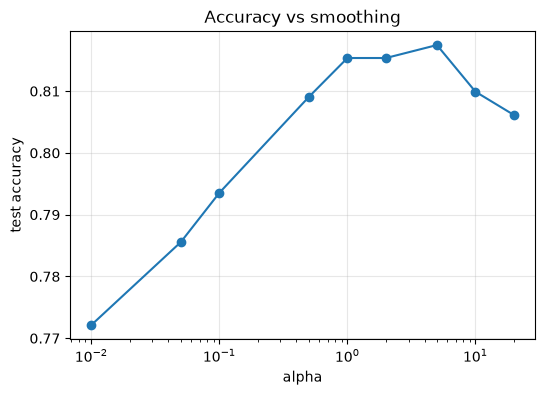

In [79]:
# Accuracy against the smoothing parameter
alphas = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
accuracies = []

for a in alphas:
    m = train_nb(train_docs, train_labels, alpha=a)
    acc = accuracy(test_labels, classify_documents(test_docs, m))
    accuracies.append(acc)
    print(a, round(acc, 4))

plt.figure(figsize=(6, 4))
plt.plot(alphas, accuracies, marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("test accuracy")
plt.title("Accuracy vs smoothing")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join("media", "accuracy-vs-alpha.png"), dpi=150, bbox_inches="tight")
plt.show()

[[1036  194]
 [ 246  907]]


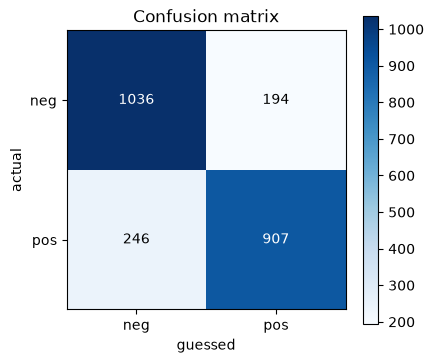

In [80]:
# Confusion matrix
labels_order = ["neg", "pos"]
matrix = np.zeros((2, 2), dtype=int)

for true_label, guess_label in zip(test_labels, guesses):
    matrix[labels_order.index(true_label), labels_order.index(guess_label)] += 1

print(matrix)

plt.figure(figsize=(4.5, 4))
plt.imshow(matrix, cmap="Blues")
plt.xticks([0, 1], labels_order)
plt.yticks([0, 1], labels_order)
plt.xlabel("guessed")
plt.ylabel("actual")
plt.title("Confusion matrix")

for i in range(2):
    for j in range(2):
        color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
        plt.text(j, i, matrix[i, j], ha="center", va="center", color=color)

plt.colorbar()
plt.savefig(os.path.join("media", "confusion-matrix.png"), dpi=150, bbox_inches="tight")
plt.show()